## Introduction

In this example, we use the ARCO data from the ECMWF rather than the download (old method).

We want to look for our data over time for Bangalore. There are two formats we can download the data in ZARR:

- **GeoChunked:** This is for long time-series analysis
- **TimeChunked:** This is for big area analysis

Here, we need the GeoChunked data format as we need to compute things over long time-series.

We follow the script given in the CDS website itself but here we adopt it for using with the .zar/ARCO data:
https://cds.climate.copernicus.eu/datasets/reanalysis-era5-single-levels-timeseries?tab=analysis_ready_data

In [ ]:
!pip install -U "xarray" "zarr" "fsspec==2025.12.0" "aiohttp" --quiet

Importing the Python packages:

In [ ]:
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt

In [ ]:
## Geo-chunked data for access along the time dimension (e.g. for time-series at a single point)
geochunked_sfc_url = "https://arco.datastores.ecmwf.int/cadl-arco-geo-002/arco/reanalysis_era5_single_levels/sfc/geoChunked.zarr"

In [ ]:
import os
cdsapi_key = "fill in your api key"

In [ ]:
# Open the zarr store with xarray, users must insert their API key where indicated.
ds = xr.open_zarr(
    geochunked_sfc_url,
    consolidated=True,
     storage_options = {
        "headers": {"Authorization": f"Bearer {cdsapi_key}"}
    }
)

# Inspect the variables
ds

<xarray.Dataset> Size: 63TB
Dimensions:    (time: 761184, latitude: 721, longitude: 1440)
Coordinates:
  * time       (time) datetime64[ns] 6MB 1940-01-01 ... 2026-10-31T23:00:00
  * latitude   (latitude) float64 6kB -90.0 -89.75 -89.5 ... 89.5 89.75 90.0
  * longitude  (longitude) float64 12kB -180.0 -179.8 -179.5 ... 179.5 179.8
Data variables: (12/20)
    blh        (time, latitude, longitude) float32 3TB dask.array<chunksize=(67584, 4, 4), meta=np.ndarray>
    cbh        (time, latitude, longitude) float32 3TB dask.array<chunksize=(67584, 4, 4), meta=np.ndarray>
    d2m        (time, latitude, longitude) float32 3TB dask.array<chunksize=(67584, 4, 4), meta=np.ndarray>
    fdir       (time, latitude, longitude) float32 3TB dask.array<chunksize=(67584, 4, 4), meta=np.ndarray>
    fg10       (time, latitude, longitude) float32 3TB dask.array<chunksize=(67584, 4, 4), meta=np.ndarray>
    msl        (time, latitude, longitude) float32 3TB dask.array<chunksize=(67584, 4, 4), meta=np.ndarray>
    ...         ...
    tcc        (time, latitude, longitude) float32 3TB dask.array<chunksize=(67584, 4, 4), meta=np.ndarray>
    tp         (time, latitude, longitude) float32 3TB dask.array<chunksize=(67584, 4, 4), meta=np.ndarray>
    u10        (time, latitude, longitude) float32 3TB dask.array<chunksize=(67584, 4, 4), meta=np.ndarray>
    u100       (time, latitude, longitude) float32 3TB dask.array<chunksize=(67584, 4, 4), meta=np.ndarray>
    v10        (time, latitude, longitude) float32 3TB dask.array<chunksize=(67584, 4, 4), meta=np.ndarray>
    v100       (time, latitude, longitude) float32 3TB dask.array<chunksize=(67584, 4, 4), meta=np.ndarray>
Attributes:
    Conventions:             CF-1.7
    GRIB_centre:             ecmf
    GRIB_centreDescription:  European Centre for Medium-Range Weather Forecasts
    GRIB_edition:            1
    GRIB_subCentre:          0
    history:                 2024-09-02T04:48 GRIB to CDM+CF via cfgrib-0.9.1...
    institution:             European Centre for Medium-Range Weather Forecasts

Expanding the variables, again we will work with the temperature data and "query" this:

In [ ]:
for var in ds.data_vars:
    print(f"\nVariable: {var}")
    print(f"Description: {ds[var].attrs.get('long_name', 'Not available')}")
    print(f"Standard name: {ds[var].attrs.get('standard_name', 'Not available')}")
    print(f"Units: {ds[var].attrs.get('units', 'Not available')}")


Variable: blh
Description: Boundary layer height
Standard name: unknown
Units: m

Variable: cbh
Description: Cloud base height
Standard name: unknown
Units: m

Variable: d2m
Description: 2 metre dewpoint temperature
Standard name: unknown
Units: K

Variable: fdir
Description: Total sky direct solar radiation at surface
Standard name: unknown
Units: J m**-2

Variable: fg10
Description: 10 metre wind gust since previous post-processing
Standard name: unknown
Units: m s**-1

Variable: msl
Description: Mean sea level pressure
Standard name: air_pressure_at_mean_sea_level
Units: Pa

Variable: skt
Description: Skin temperature
Standard name: unknown
Units: K

Variable: slhf
Description: Surface latent heat flux
Standard name: surface_upward_latent_heat_flux
Units: J m**-2

Variable: sp
Description: Surface pressure
Standard name: surface_air_pressure
Units: Pa

Variable: sshf
Description: Surface sensible heat flux
Standard name: surface_upward_sensible_heat_flux
Units: J m**-2

Variable: s

Put into a data array:

In [ ]:
t2m = ds["t2m"]
t2m

<xarray.DataArray 't2m' (time: 761184, latitude: 721, longitude: 1440)> Size: 3TB
dask.array<open_dataset-t2m, shape=(761184, 721, 1440), dtype=float32, chunksize=(67584, 4, 4), chunktype=numpy.ndarray>
Coordinates:
  * time       (time) datetime64[ns] 6MB 1940-01-01 ... 2026-10-31T23:00:00
  * latitude   (latitude) float64 6kB -90.0 -89.75 -89.5 ... 89.5 89.75 90.0
  * longitude  (longitude) float64 12kB -180.0 -179.8 -179.5 ... 179.5 179.8
Attributes: (12/30)
    GRIB_NV:                                  0
    GRIB_Nx:                                  1440
    GRIB_Ny:                                  721
    GRIB_cfName:                              unknown
    GRIB_cfVarName:                           t2m
    GRIB_dataType:                            an
    ...                                       ...
    GRIB_totalNumber:                         0
    GRIB_typeOfLevel:                         surface
    GRIB_units:                               K
    long_name:                                2 metre temperature
    standard_name:                            unknown
    units:                                    K

In [ ]:
t2m.shape

(761184, 721, 1440)

In [ ]:
t2m.encoding["chunks"]

(67584, 4, 4)

In [ ]:
t2m.time

<xarray.DataArray 'time' (time: 761184)> Size: 6MB
array(['1940-01-01T00:00:00.000000000', '1940-01-01T01:00:00.000000000',
       '1940-01-01T02:00:00.000000000', ..., '2026-10-31T21:00:00.000000000',
       '2026-10-31T22:00:00.000000000', '2026-10-31T23:00:00.000000000'],
      shape=(761184,), dtype='datetime64[ns]')
Coordinates:
  * time     (time) datetime64[ns] 6MB 1940-01-01 ... 2026-10-31T23:00:00

Select only the months of september:

In [ ]:
t2m_september = t2m.where(
    (t2m.time.dt.month == 9) &
    (t2m.time.dt.year >= 1979),
    drop=True
)

In [ ]:
t2m_september

<xarray.DataArray 't2m' (time: 34560, latitude: 721, longitude: 1440)> Size: 144GB
dask.array<where, shape=(34560, 721, 1440), dtype=float32, chunksize=(34560, 4, 4), chunktype=numpy.ndarray>
Coordinates:
  * time       (time) datetime64[ns] 276kB 1979-09-01 ... 2026-09-30T23:00:00
  * latitude   (latitude) float64 6kB -90.0 -89.75 -89.5 ... 89.5 89.75 90.0
  * longitude  (longitude) float64 12kB -180.0 -179.8 -179.5 ... 179.5 179.8
Attributes: (12/30)
    GRIB_NV:                                  0
    GRIB_Nx:                                  1440
    GRIB_Ny:                                  721
    GRIB_cfName:                              unknown
    GRIB_cfVarName:                           t2m
    GRIB_dataType:                            an
    ...                                       ...
    GRIB_totalNumber:                         0
    GRIB_typeOfLevel:                         surface
    GRIB_units:                               K
    long_name:                                2 metre temperature
    standard_name:                            unknown
    units:                                    K

Select only for the region of Bangalore:

In [ ]:
t2m_bangalore = t2m_september.sel(
    longitude=slice(77, 78),
    latitude=slice(12, 14)
)

In [ ]:
t2m_bangalore

<xarray.DataArray 't2m' (time: 34560, latitude: 9, longitude: 5)> Size: 6MB
dask.array<getitem, shape=(34560, 9, 5), dtype=float32, chunksize=(34560, 4, 4), chunktype=numpy.ndarray>
Coordinates:
  * time       (time) datetime64[ns] 276kB 1979-09-01 ... 2026-09-30T23:00:00
  * latitude   (latitude) float64 72B 12.0 12.25 12.5 12.75 ... 13.5 13.75 14.0
  * longitude  (longitude) float64 40B 77.0 77.25 77.5 77.75 78.0
Attributes: (12/30)
    GRIB_NV:                                  0
    GRIB_Nx:                                  1440
    GRIB_Ny:                                  721
    GRIB_cfName:                              unknown
    GRIB_cfVarName:                           t2m
    GRIB_dataType:                            an
    ...                                       ...
    GRIB_totalNumber:                         0
    GRIB_typeOfLevel:                         surface
    GRIB_units:                               K
    long_name:                                2 metre temperature
    standard_name:                            unknown
    units:                                    K

In [ ]:
print(t2m_bangalore.longitude.values)
print(t2m_bangalore.latitude.values)

[77.   77.25 77.5  77.75 78.  ]
[12.   12.25 12.5  12.75 13.   13.25 13.5  13.75 14.  ]


Now, we are ready to "call" the dataset. You can "load" or "compute".

In [ ]:
%time
t2m_bangalore = t2m_bangalore.load()
t2m_bangalore

CPU times: user 4 µs, sys: 0 ns, total: 4 µs
Wall time: 8.11 µs


<xarray.DataArray 't2m' (time: 34560, latitude: 9, longitude: 5)> Size: 6MB
array([[[293.55792, 294.67706, 296.18097, 296.27277, 295.67706],
        [295.47394, 296.55402, 296.24933, 295.59894, 295.6595 ],
        [295.02277, 295.58136, 294.9427 , 294.45245, 295.12823],
        ...,
        [294.25714, 294.1634 , 294.19073, 294.11652, 294.1673 ],
        [294.62238, 294.9134 , 294.94073, 294.92706, 294.972  ],
        [294.9583 , 295.30988, 296.12433, 296.12042, 295.96027]],

       [[293.73682, 294.7251 , 296.00635, 296.08643, 295.55127],
        [295.11182, 296.30322, 296.18213, 295.55127, 295.49854],
        [295.15283, 295.34424, 294.77197, 294.44385, 295.10596],
        ...,
        [294.1997 , 294.31104, 294.37158, 294.18994, 294.27002],
        [294.604  , 294.79736, 294.86377, 294.95166, 295.03174],
        [294.88916, 295.11377, 295.84424, 295.9419 , 295.94385]],

       [[294.57043, 294.8888 , 295.86145, 295.90637, 295.2599 ],
        [295.51184, 296.1173 , 296.00793, 295.41028, 295.21106],
        [295.53918, 295.4884 , 294.78137, 294.40637, 295.07825],
        ...,
...
        [295.51837, 295.6043 , 295.56915, 295.57892, 295.9715 ],
        [296.23517, 296.39142, 296.3543 , 296.21368, 296.59845],
        [296.70782, 296.81915, 297.31915, 297.18048, 297.5672 ]],

       [[294.21783, 294.35846, 295.81354, 296.72565, 296.64557],
        [295.1651 , 295.3604 , 295.41705, 295.69244, 296.26862],
        [295.65338, 295.3604 , 294.50104, 294.29205, 295.42487],
        ...,
        [295.11823, 295.01862, 295.00494, 295.05963, 295.46783],
        [295.77838, 295.9073 , 295.89166, 295.89166, 296.29205],
        [296.42877, 296.5401 , 296.93658, 296.9405 , 297.27643]],

       [[294.2035 , 294.29333, 295.63318, 296.5609 , 296.63513],
        [295.26794, 295.4242 , 295.44177, 295.66052, 296.16833],
        [295.6996 , 295.3949 , 294.52185, 294.25818, 295.29333],
        ...,
        [294.90662, 294.682  , 294.91638, 294.98865, 295.25623],
        [295.4906 , 295.59802, 295.84216, 295.91248, 296.16833],
        [296.1703 , 296.28943, 296.7328 , 296.807  , 297.18982]]],
      shape=(34560, 9, 5), dtype=float32)
Coordinates:
  * time       (time) datetime64[ns] 276kB 1979-09-01 ... 2026-09-30T23:00:00
  * latitude   (latitude) float64 72B 12.0 12.25 12.5 12.75 ... 13.5 13.75 14.0
  * longitude  (longitude) float64 40B 77.0 77.25 77.5 77.75 78.0
Attributes: (12/30)
    GRIB_NV:                                  0
    GRIB_Nx:                                  1440
    GRIB_Ny:                                  721
    GRIB_cfName:                              unknown
    GRIB_cfVarName:                           t2m
    GRIB_dataType:                            an
    ...                                       ...
    GRIB_totalNumber:                         0
    GRIB_typeOfLevel:                         surface
    GRIB_units:                               K
    long_name:                                2 metre temperature
    standard_name:                            unknown
    units:                                    K

## Heat analysis

We follow the same analysis as before:

In [ ]:
print("shape:", t2m_bangalore.shape)

shape: (34560, 9, 5)


Convert the data into Celsius:

In [ ]:
t2m_sep_C = t2m_bangalore - 273.15
t2m_sep_C

<xarray.DataArray 't2m' (time: 34560, latitude: 9, longitude: 5)> Size: 6MB
array([[[20.407928, 21.52707 , 23.030975, 23.122772, 22.52707 ],
        [22.323944, 23.404022, 23.099335, 22.448944, 22.509491],
        [21.872772, 22.431366, 21.792694, 21.30246 , 21.978241],
        ...,
        [21.107147, 21.013397, 21.040741, 20.966522, 21.017303],
        [21.472382, 21.763397, 21.790741, 21.77707 , 21.821991],
        [21.80832 , 22.159882, 22.974335, 22.970428, 22.810272]],

       [[20.586823, 21.575104, 22.856354, 22.936432, 22.401276],
        [21.961823, 23.153229, 23.032135, 22.401276, 22.348541],
        [22.002838, 22.194244, 21.621979, 21.293854, 21.955963],
        ...,
        [21.049713, 21.161041, 21.221588, 21.039948, 21.120026],
        [21.45401 , 21.64737 , 21.713776, 21.801666, 21.881744],
        [21.739166, 21.963776, 22.694244, 22.7919  , 22.793854]],

       [[21.42044 , 21.7388  , 22.711456, 22.756378, 22.109894],
        [22.361847, 22.967316, 22.85794 , 22.260284, 22.061066],
        [22.38919 , 22.33841 , 21.631378, 21.256378, 21.928253],
        ...,
...
        [22.368378, 22.454315, 22.419159, 22.428925, 22.821503],
        [23.085175, 23.241425, 23.204315, 23.06369 , 23.448456],
        [23.55783 , 23.669159, 24.169159, 24.030487, 24.417206]],

       [[21.06784 , 21.208466, 22.663544, 23.575653, 23.495575],
        [22.015106, 22.210419, 22.26706 , 22.54245 , 23.118622],
        [22.503387, 22.210419, 21.351044, 21.14206 , 22.274872],
        ...,
        [21.968231, 21.868622, 21.85495 , 21.909637, 22.31784 ],
        [22.628387, 22.757294, 22.741669, 22.741669, 23.14206 ],
        [23.278778, 23.390106, 23.78659 , 23.790497, 24.126434]],

       [[21.053497, 21.143341, 22.483185, 23.41092 , 23.485138],
        [22.11795 , 22.2742  , 22.291779, 22.510529, 23.018341],
        [22.549591, 22.244904, 21.371857, 21.108185, 22.143341],
        ...,
        [21.756622, 21.532013, 21.766388, 21.838654, 22.106232],
        [22.340607, 22.448029, 22.69217 , 22.762482, 23.018341],
        [23.020294, 23.139435, 23.582794, 23.657013, 24.039825]]],
      shape=(34560, 9, 5), dtype=float32)
Coordinates:
  * time       (time) datetime64[ns] 276kB 1979-09-01 ... 2026-09-30T23:00:00
  * latitude   (latitude) float64 72B 12.0 12.25 12.5 12.75 ... 13.5 13.75 14.0
  * longitude  (longitude) float64 40B 77.0 77.25 77.5 77.75 78.0
Attributes: (12/30)
    GRIB_NV:                                  0
    GRIB_Nx:                                  1440
    GRIB_Ny:                                  721
    GRIB_cfName:                              unknown
    GRIB_cfVarName:                           t2m
    GRIB_dataType:                            an
    ...                                       ...
    GRIB_totalNumber:                         0
    GRIB_typeOfLevel:                         surface
    GRIB_units:                               K
    long_name:                                2 metre temperature
    standard_name:                            unknown
    units:                                    K

In [ ]:
t2m_sep_C.time

<xarray.DataArray 'time' (time: 34560)> Size: 276kB
array(['1979-09-01T00:00:00.000000000', '1979-09-01T01:00:00.000000000',
       '1979-09-01T02:00:00.000000000', ..., '2026-09-30T21:00:00.000000000',
       '2026-09-30T22:00:00.000000000', '2026-09-30T23:00:00.000000000'],
      shape=(34560,), dtype='datetime64[ns]')
Coordinates:
  * time     (time) datetime64[ns] 276kB 1979-09-01 ... 2026-09-30T23:00:00

Correct the latitude (as at the poles the cells are not the same). Not sure how it matters for Bangalore :):

In [ ]:
weights = np.cos(np.deg2rad(t2m_sep_C.latitude))
weights

<xarray.DataArray 'latitude' (latitude: 9)> Size: 72B
array([0.9781476 , 0.97723111, 0.97629601, 0.97534232, 0.97437006,
       0.97337926, 0.97236992, 0.97134207, 0.97029573])
Coordinates:
  * latitude  (latitude) float64 72B 12.0 12.25 12.5 12.75 ... 13.5 13.75 14.0
Attributes:
    long_name:         latitude
    standard_name:     latitude
    stored_direction:  decreasing
    units:             degrees_north

In [ ]:
## We follow the tutorial and correct the data:
t2m_sep_C_weighted = t2m_sep_C.weighted(weights)

The following script takes the mean over the latitude and longitude and this for each hour and each day of the month September across all the years (34 560 observations in time):

In [ ]:
bangalore_sep_t2m = t2m_sep_C_weighted.mean(["longitude", "latitude"])
bangalore_sep_t2m

<xarray.DataArray 't2m' (time: 34560)> Size: 276kB
array([21.63395105, 21.60074445, 22.00717103, ..., 22.53315843,
       22.18079689, 22.08309492], shape=(34560,))
Coordinates:
  * time     (time) datetime64[ns] 276kB 1979-09-01 ... 2026-09-30T23:00:00
Attributes: (12/30)
    GRIB_NV:                                  0
    GRIB_Nx:                                  1440
    GRIB_Ny:                                  721
    GRIB_cfName:                              unknown
    GRIB_cfVarName:                           t2m
    GRIB_dataType:                            an
    ...                                       ...
    GRIB_totalNumber:                         0
    GRIB_typeOfLevel:                         surface
    GRIB_units:                               K
    long_name:                                2 metre temperature
    standard_name:                            unknown
    units:                                    K

Select the data only for 2026:

In [ ]:
bangalore_sep_t2m_2026 = bangalore_sep_t2m.sel(time='2026')
bangalore_sep_t2m_2026

<xarray.DataArray 't2m' (time: 720)> Size: 6kB
array([22.99964984, 23.19344609, 24.03105257, 24.43927506, 24.97275655,
       27.05571985, 29.00166163, 29.25763921, 30.30430495, 30.75001605,
       29.39205952, 29.14404872, 28.70948561, 28.454569  , 27.8967023 ,
       25.79385461, 25.44570168, 24.72802692, 24.45161609, 24.06596601,
       23.14524988, 22.66106715, 22.10753457, 22.05375381, 23.36248745,
       23.38466007, 24.29864597, 24.68231454, 25.23561114, 26.89244662,
       29.23506935, 29.66856158, 31.01322597, 31.42072345, 30.13452862,
       29.93281767, 29.56346076, 29.30341654, 28.4613264 , 26.39070335,
       25.56269199, 24.65582576, 24.11183525, 23.86549643, 23.06465783,
       22.37909137, 21.99584216, 21.77202383, 23.20249428, 23.45653519,
       24.16668509, 24.59119338, 25.09146301, 26.90353156, 29.37115066,
       30.01211294, 30.43418311, 30.51668382, 29.01592636, 28.91700363,
       28.62721242, 28.53966162, 27.98606674, 26.10716727, 25.86912574,
       24.88607898, 24.57556343, 24.08693802, 23.3030404 , 22.78614523,
       22.4675857 , 22.22345739, 23.38301616, 23.50029769, 24.02010852,
       24.44430882, 25.12076038, 26.91021174, 29.26168348, 29.90848339,
       30.88212972, 31.1209881 , 30.49502534, 30.4486558 , 30.31886613,
       30.11507365, 29.18298203, 26.76077791, 26.50181255, 25.20242367,
       24.78202031, 24.34981169, 23.73363145, 23.22837269, 22.63268738,
       22.3744784 , 23.23556116, 23.2181859 , 24.24522403, 24.78537864,
...
       22.59230944, 22.08897993, 21.16971483, 21.02359831, 22.69049451,
       22.87814622, 24.09278985, 24.66839521, 25.48906563, 27.848042  ,
       30.30961127, 30.92774574, 32.29047408, 32.63903943, 31.67216545,
       31.62864771, 31.30459003, 30.5033486 , 29.25440654, 27.03346127,
       26.50848897, 25.37473597, 24.98465937, 24.54181897, 24.28293773,
       23.81019393, 23.53046601, 23.18794763, 24.42595442, 24.35313786,
       25.30239384, 25.66671099, 25.97844271, 27.53172614, 29.96465808,
       30.44507784, 31.40929042, 31.66311136, 30.07482251, 29.75175511,
       29.40681116, 28.7498729 , 27.81845236, 25.27424956, 25.15808685,
       24.20791589, 24.16769695, 24.11362735, 23.80916666, 23.76778885,
       23.77360478, 23.60835991, 24.31212012, 24.24903208, 24.58159757,
       24.41516816, 24.87639352, 26.34466174, 28.02365456, 28.4492349 ,
       29.61432758, 30.10121475, 29.62207941, 29.52976096, 29.22674872,
       28.69443617, 27.84093375, 25.95999025, 25.70793179, 25.15357457,
       24.96181701, 24.58396817, 24.05071539, 23.86002209, 23.63004043,
       23.50795616, 24.33633762, 24.26603585, 24.6855863 , 25.02909474,
       25.75359398, 27.68411189, 30.08607591, 30.69664378, 31.6229038 ,
       31.64082273, 29.81194186, 29.10863454, 27.04273075, 26.80361258,
       26.5275914 , 24.50575612, 24.123849  , 23.52957479, 23.52382362,
       23.34671888, 22.70519043, 22.53315843, 22.18079689, 22.08309492])
Coordinates:
  * time     (time) datetime64[ns] 6kB 2026-09-01 ... 2026-09-30T23:00:00
Attributes: (12/30)
    GRIB_NV:                                  0
    GRIB_Nx:                                  1440
    GRIB_Ny:                                  721
    GRIB_cfName:                              unknown
    GRIB_cfVarName:                           t2m
    GRIB_dataType:                            an
    ...                                       ...
    GRIB_totalNumber:                         0
    GRIB_typeOfLevel:                         surface
    GRIB_units:                               K
    long_name:                                2 metre temperature
    standard_name:                            unknown
    units:                                    K

For each of the days in the month of September for the year 2026, we compute the maximum temperatures from the hourly observations.

In [ ]:
bangalore_2026_max = bangalore_sep_t2m_2026.groupby('time.day').max('time')
bangalore_2026_max

<xarray.DataArray 't2m' (day: 30)> Size: 240B
array([30.75001605, 31.42072345, 30.51668382, 31.1209881 , 33.40230244,
       32.84349378, 32.8558596 , 32.76158508, 31.68915012, 32.15046482,
       32.16549138, 33.09000109, 32.06837395, 32.75419221, 33.52486714,
       33.60223844, 33.26718219, 32.54521869, 32.92620064, 30.63148574,
       30.7210392 , 30.82041859, 27.66882737, 29.52705007, 29.27848982,
       31.72161696, 32.63903943, 31.66311136, 30.10121475, 31.64082273])
Coordinates:
  * day      (day) int64 240B 1 2 3 4 5 6 7 8 9 ... 22 23 24 25 26 27 28 29 30
Attributes: (12/30)
    GRIB_NV:                                  0
    GRIB_Nx:                                  1440
    GRIB_Ny:                                  721
    GRIB_cfName:                              unknown
    GRIB_cfVarName:                           t2m
    GRIB_dataType:                            an
    ...                                       ...
    GRIB_totalNumber:                         0
    GRIB_typeOfLevel:                         surface
    GRIB_units:                               K
    long_name:                                2 metre temperature
    standard_name:                            unknown
    units:                                    K

We have reduced the data now to temperature data for each day. Let's plot this:

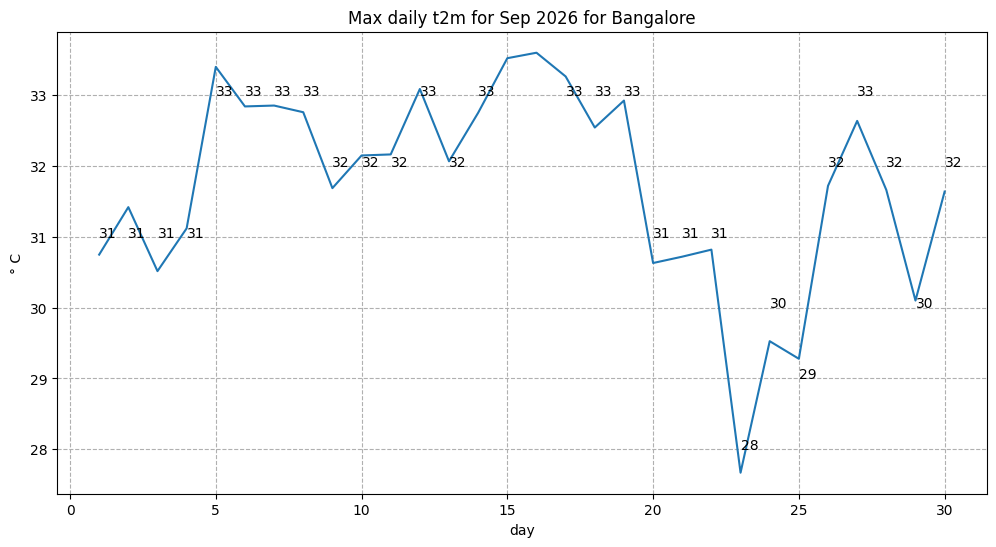

In [ ]:
## Code obtained from:
fig, ax = plt.subplots(1, 1, figsize = (12, 6))

ax.plot(bangalore_2026_max.day, bangalore_2026_max)
ax.set_title('Max daily t2m for Sep 2026 for Bangalore')
ax.set_ylabel('° C')
ax.set_xlabel('day')
ax.grid(linestyle='--')
for i,j in zip(bangalore_2026_max.day, np.around(bangalore_2026_max.values, 0).astype(int)):
    ax.annotate(str(j),xy=(i,j))
fig.savefig('max_t2_bangalore_time_series.png')

In [ ]:
print('The maximum temperature in September 2026 in Bangalore was',
      np.around(bangalore_2026_max.max().values, 1), 'degrees Celsius.')

The maximum temperature in September 2026 in Bangalore was 33.6 degrees Celsius.


## Long-term temperature values

We go back to the bangalore_sep_t2m DataArray and select all the data before 2026:

In [ ]:
bangalore_sep_t2m_before_2026 = bangalore_sep_t2m.loc['1979':'2025']

In xarray, you can "slice" data. Also see above with using the "sel" method.

There is also something called .loc and .iloc. For more information regarding [Indexing and Slicing](https://docs.xarray.dev/en/stable/user-guide/indexing.html), please find the xarray documentation in this link.

Before computing the daily long term averages across all the years from the daily data, we compute the maximum values for each of the days in September for the entire period 1979-2025. We do so using a "resampling" method in xarray meaning we "reduce" according to a certain dimension (days here).


In [ ]:
bangalore_max = bangalore_sep_t2m_before_2026.resample(time='D').max().dropna('time')
bangalore_max

<xarray.DataArray 't2m' (time: 1410)> Size: 11kB
array([30.18964365, 28.31653406, 28.71572639, ..., 28.73401607,
       29.0322916 , 29.2972405 ], shape=(1410,))
Coordinates:
  * time     (time) datetime64[ns] 11kB 1979-09-01 1979-09-02 ... 2025-09-30
Attributes: (12/30)
    GRIB_NV:                                  0
    GRIB_Nx:                                  1440
    GRIB_Ny:                                  721
    GRIB_cfName:                              unknown
    GRIB_cfVarName:                           t2m
    GRIB_dataType:                            an
    ...                                       ...
    GRIB_totalNumber:                         0
    GRIB_typeOfLevel:                         surface
    GRIB_units:                               K
    long_name:                                2 metre temperature
    standard_name:                            unknown
    units:                                    K

In [ ]:
bangalore_max.time

<xarray.DataArray 'time' (time: 1410)> Size: 11kB
array(['1979-09-01T00:00:00.000000000', '1979-09-02T00:00:00.000000000',
       '1979-09-03T00:00:00.000000000', ..., '2025-09-28T00:00:00.000000000',
       '2025-09-29T00:00:00.000000000', '2025-09-30T00:00:00.000000000'],
      shape=(1410,), dtype='datetime64[ns]')
Coordinates:
  * time     (time) datetime64[ns] 11kB 1979-09-01 1979-09-02 ... 2025-09-30

For each day, compute several statistics over the years now. Notice that here, we use another "reducer" called "groupby". We again find more information for this in the xarray tutorials here.

In [ ]:
bangalore_max_max = bangalore_max.groupby('time.day').max()
bangalore_max_min = bangalore_max.groupby('time.day').min()
bangalore_max_mid = bangalore_max.groupby('time.day').quantile(0.5)

The following data array prints out for each day the hottest temperature across all the years:

In [ ]:
bangalore_max_max

<xarray.DataArray 't2m' (day: 30)> Size: 240B
array([31.87805377, 31.44541189, 31.61690131, 32.10315435, 30.66236548,
       31.93196044, 31.66096465, 31.46380347, 30.87684841, 31.29798414,
       31.26743127, 32.0141058 , 32.32124861, 32.22982254, 31.73297994,
       31.06740071, 31.39411995, 31.14026041, 31.74198554, 31.37659131,
       31.66253657, 32.31828518, 31.55871162, 31.94887297, 31.51560483,
       31.40601186, 31.65636607, 31.98906575, 31.4695573 , 31.46698321])
Coordinates:
  * day      (day) int64 240B 1 2 3 4 5 6 7 8 9 ... 22 23 24 25 26 27 28 29 30
Attributes: (12/30)
    GRIB_NV:                                  0
    GRIB_Nx:                                  1440
    GRIB_Ny:                                  721
    GRIB_cfName:                              unknown
    GRIB_cfVarName:                           t2m
    GRIB_dataType:                            an
    ...                                       ...
    GRIB_totalNumber:                         0
    GRIB_typeOfLevel:                         surface
    GRIB_units:                               K
    long_name:                                2 metre temperature
    standard_name:                            unknown
    units:                                    K

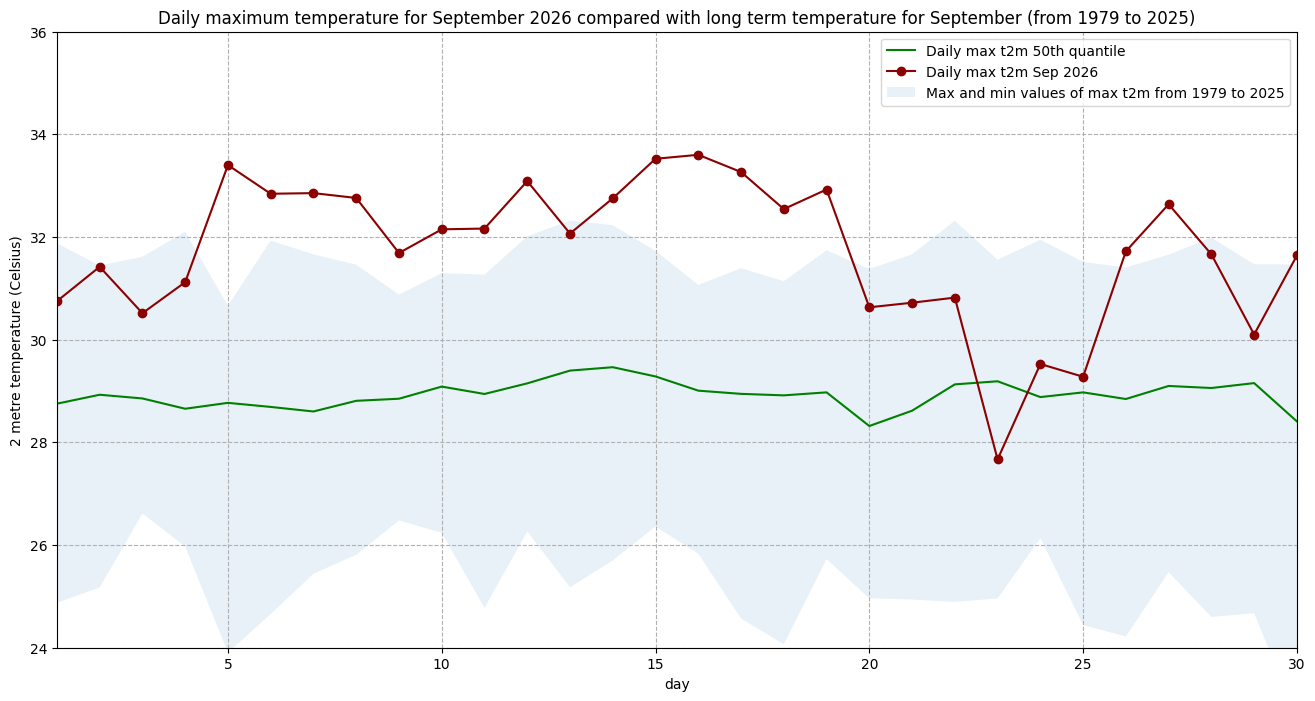

In [ ]:
## Code based on:
## https://ecmwf-projects.github.io/copernicus-training-c3s/reanalysis-heatwave.html
fig = plt.figure(figsize=(16,8))
ax = plt.subplot()

ax.plot(bangalore_2026_max.day.day, bangalore_max_mid, color='green', label='Daily max t2m 50th quantile')
ax.plot(bangalore_2026_max.day.day, bangalore_2026_max, 'o-', color='darkred', label='Daily max t2m Sep 2026')
ax.fill_between(bangalore_2026_max.day, bangalore_max_max, bangalore_max_min, alpha=0.1,
                label='Max and min values of max t2m from 1979 to 2025')

ax.set_xlim(1,30)
ax.set_ylim(24,36)
ax.set_title('Daily maximum temperature for September 2026 compared with long term temperature for September (from 1979 to 2025)')
ax.set_ylabel('2 metre temperature (Celsius)')
ax.set_xlabel('day')
handles, labels = ax.get_legend_handles_labels()
ax.legend(handles, labels)
ax.grid(linestyle='--')

fig.savefig('max_t2m_Sep_bangalore_comparison_2026_geochunked.png')

## References

https://github.com/ecmwf-training/dss-notebooks/blob/main/datasets/reanalysis-era5-single-levels/arco-access.ipynb

https://cds.climate.copernicus.eu/datasets/reanalysis-era5-single-levels-timeseries?tab=analysis_ready_data